# Stroke Prediction

**Data:** [Stroke Prediction Dataset](https://www.kaggle.com/datasets/fedesoriano/stroke-prediction-dataset) by fedesoriano

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_style("whitegrid")

In [2]:
heal = pd.read_csv('/kaggle/input/datasets/fedesoriano/stroke-prediction-dataset/healthcare-dataset-stroke-data.csv')
heal.head()

,id,gender,age,hypertension,heart_disease,ever_married,work_type,Residence_type,avg_glucose_level,bmi,smoking_status,stroke
0,9046,Male,67.0,0,1,Yes,Private,Urban,228.69,36.6,formerly smoked,1
1,51676,Female,61.0,0,0,Yes,Self-employed,Rural,202.21,NaN,never smoked,1
2,31112,Male,80.0,0,1,Yes,Private,Rural,105.92,32.5,never smoked,1
3,60182,Female,49.0,0,0,Yes,Private,Urban,171.23,34.4,smokes,1
4,1665,Female,79.0,1,0,Yes,Self-employed,Rural,174.12,24.0,never smoked,1


In [3]:
heal.sample(10)

,id,gender,age,hypertension,heart_disease,ever_married,work_type,Residence_type,avg_glucose_level,bmi,smoking_status,stroke
4583,37515,Female,46.0,0,0,Yes,Govt_job,Rural,76.43,22.7,Unknown,0
4134,18178,Female,48.0,0,0,Yes,Private,Urban,86.06,36.2,never smoked,0
4823,7218,Female,79.0,0,0,Yes,Private,Rural,214.73,30.9,never smoked,0
1164,53276,Female,49.0,0,0,Yes,Private,Urban,67.55,17.6,formerly smoked,0
3410,28315,Male,38.0,0,0,Yes,Private,Rural,108.68,32.7,never smoked,0
4521,34130,Male,54.0,1,0,Yes,Private,Rural,116.44,24.5,never smoked,0
1682,14711,Male,63.0,0,0,Yes,Self-employed,Urban,82.08,32.2,formerly smoked,0
369,8171,Female,4.0,0,0,No,children,Rural,93.25,16.6,Unknown,0
3884,44642,Male,52.0,0,0,Yes,Govt_job,Urban,93.28,36.3,never smoked,0
1951,1460,Female,82.0,0,0,Yes,Private,Urban,99.68,22.2,Unknown,0


In [4]:
heal.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5110 entries, 0 to 5109
Data columns (total 12 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   id                 5110 non-null   int64  
 1   gender             5110 non-null   object 
 2   age                5110 non-null   float64
 3   hypertension       5110 non-null   int64  
 4   heart_disease      5110 non-null   int64  
 5   ever_married       5110 non-null   object 
 6   work_type          5110 non-null   object 
 7   Residence_type     5110 non-null   object 
 8   avg_glucose_level  5110 non-null   float64
 9   bmi                4909 non-null   float64
 10  smoking_status     5110 non-null   object 
 11  stroke             5110 non-null   int64  
dtypes: float64(3), int64(4), object(5)
memory usage: 479.2+ KB


In [5]:
heal.isna().sum()

id                     0
gender                 0
age                    0
hypertension           0
heart_disease          0
ever_married           0
work_type              0
Residence_type         0
avg_glucose_level      0
bmi                  201
smoking_status         0
stroke                 0
dtype: int64

In [6]:
heal.isna().sum()*100/len(heal)

id                   0.000000
gender               0.000000
age                  0.000000
hypertension         0.000000
heart_disease        0.000000
ever_married         0.000000
work_type            0.000000
Residence_type       0.000000
avg_glucose_level    0.000000
bmi                  3.933464
smoking_status       0.000000
stroke               0.000000
dtype: float64

In [7]:
heal['gender'].value_counts()*100/len(heal)

gender
Female    58.590998
Male      41.389432
Other      0.019569
Name: count, dtype: float64

In [8]:
def count (x):
    for colum in x.select_dtypes(include='object'):
       y=  (x[colum].value_counts()*100/len(x)).round(2).to_dict()
       print(f'{colum} : {y}')
       print('-' * 30)
count(heal)

gender : {'Female': 58.59, 'Male': 41.39, 'Other': 0.02}
------------------------------
ever_married : {'Yes': 65.62, 'No': 34.38}
------------------------------
work_type : {'Private': 57.24, 'Self-employed': 16.03, 'children': 13.44, 'Govt_job': 12.86, 'Never_worked': 0.43}
------------------------------
Residence_type : {'Urban': 50.8, 'Rural': 49.2}
------------------------------
smoking_status : {'never smoked': 37.03, 'Unknown': 30.22, 'formerly smoked': 17.32, 'smokes': 15.44}
------------------------------


In [9]:
heal['stroke'].value_counts()

stroke
0    4861
1     249
Name: count, dtype: int64

Text(0.5, 1.0, 'Target  Distrbution (stroke)')

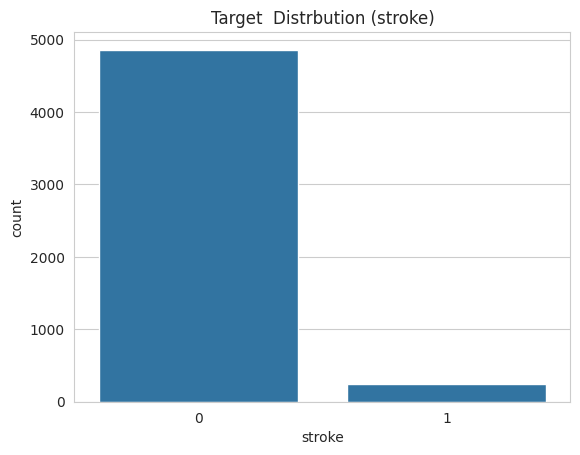

In [10]:
# sns.countplot(x='stroke',data=heal)
sns.countplot(x=heal['stroke'])
plt.title('Target  Distrbution (stroke)')

In [11]:
# heal = heal[(heal['gender']=='Male') & (heal['gender']=='Femal')]
heal = heal[heal['gender']!='Other'].reset_index(drop=True)

In [12]:
heal['gender'].value_counts()

gender
Female    2994
Male      2115
Name: count, dtype: int64

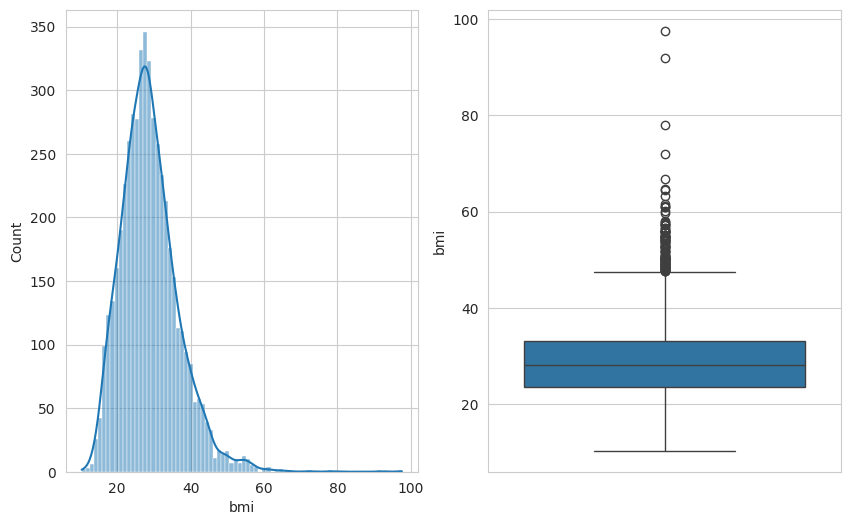

In [13]:
plt.figure(figsize=(10,6))
plt.subplot(1,2,1)
sns.histplot(heal['bmi'].dropna(), kde=True)
plt.subplot(1,2,2)
sns.boxplot(heal['bmi'])
plt.show()

In [14]:
heal['bmi'].mean().round(2)

np.float64(28.89)

In [15]:
heal['bmi'].median()

28.1

In [16]:
heal['bmi']=heal['bmi'].fillna(heal['bmi'].median())

In [17]:
heal['bmi'].isna().sum()

np.int64(0)

In [18]:
heal['smoking_status'].value_counts() *100/len(heal)

smoking_status
never smoked       37.032687
Unknown            30.221178
formerly smoked    17.302799
smokes             15.443335
Name: count, dtype: float64

In [19]:
heal.columns

Index(['id', 'gender', 'age', 'hypertension', 'heart_disease', 'ever_married',
       'work_type', 'Residence_type', 'avg_glucose_level', 'bmi',
       'smoking_status', 'stroke'],
      dtype='object')

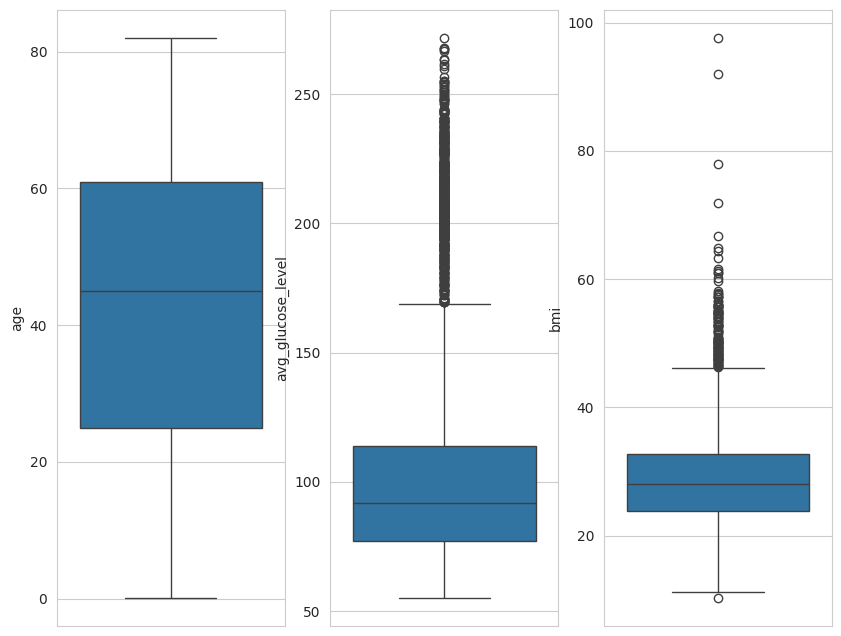

In [20]:
numic_cols = ['age','avg_glucose_level','bmi']
plt.figure(figsize=(10,8))
for i,col in enumerate(numic_cols,start=1):
    
    plt.subplot(1,3,i)
    sns.boxplot(y=col ,data=heal)
plt.show()



In [21]:
def iqr (col,k=1.5):
    q1=col.quantile(0.25)
    q3=col.quantile(0.75)
    IQR=q3-q1
    return q1-k*IQR, q3+k*IQR

In [22]:
def iqr (col,k=1.5):
    q1=col.quantile(0.25)
    q3=col.quantile(0.75)
    IQR=q3-q1
    lower= q1-k*IQR
    height= q3+k*IQR
    print(f'lower:{lower} .... height:{height} ')
    

In [23]:
for col in numic_cols:
    print(col)
    iqr(heal[col])
    print('*'*30)

age
lower:-29.0 .... height:115.0 
******************************
avg_glucose_level
lower:21.964999999999982 .... height:169.365 
******************************
bmi
lower:10.300000000000006 .... height:46.29999999999999 
******************************


In [24]:
heal['bmi']=heal['bmi'].clip(upper=62,lower=10)

<Axes: ylabel='bmi'>

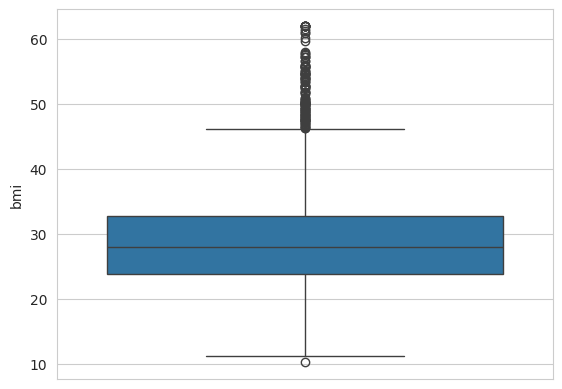

In [25]:
sns.boxplot(y=heal['bmi'])

In [26]:
numic_cols

['age', 'avg_glucose_level', 'bmi']

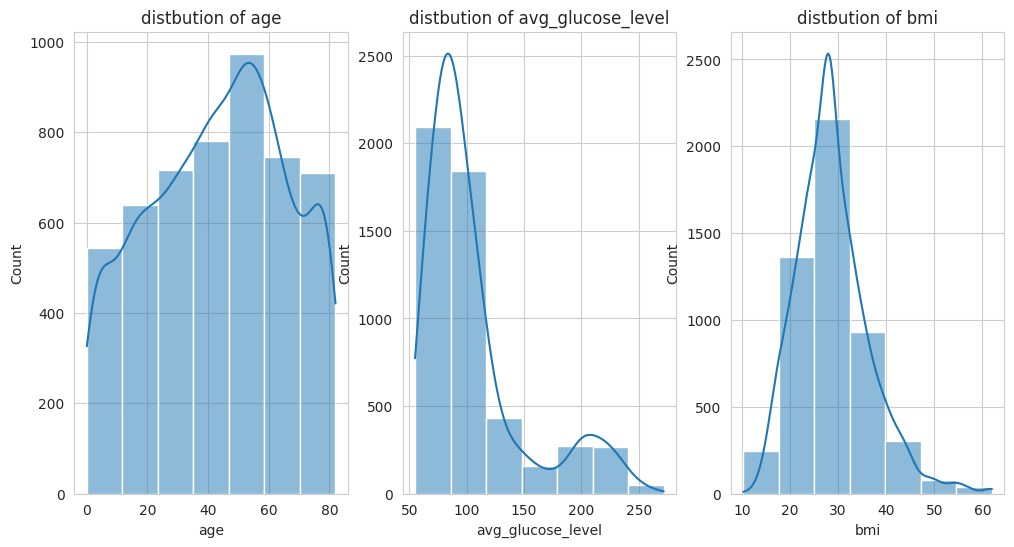

In [27]:
plt.figure(figsize=(12,6))
for i ,col in enumerate(numic_cols,start=1):
    plt.subplot(1,3,i)
    sns.histplot(x=col,bins=7,data=heal,kde=True)
    plt.title(f'distbution of {col}')
    plt.xlabel(col)
plt.show()

In [28]:
cat_cols=heal.select_dtypes(include='object')
cat_cols

,gender,ever_married,work_type,Residence_type,smoking_status
0,Male,Yes,Private,Urban,formerly smoked
1,Female,Yes,Self-employed,Rural,never smoked
2,Male,Yes,Private,Rural,never smoked
3,Female,Yes,Private,Urban,smokes
4,Female,Yes,Self-employed,Rural,never smoked
...,...,...,...,...,...
5104,Female,Yes,Private,Urban,never smoked
5105,Female,Yes,Self-employed,Urban,never smoked
5106,Female,Yes,Self-employed,Rural,never smoked
5107,Male,Yes,Private,Rural,formerly smoked


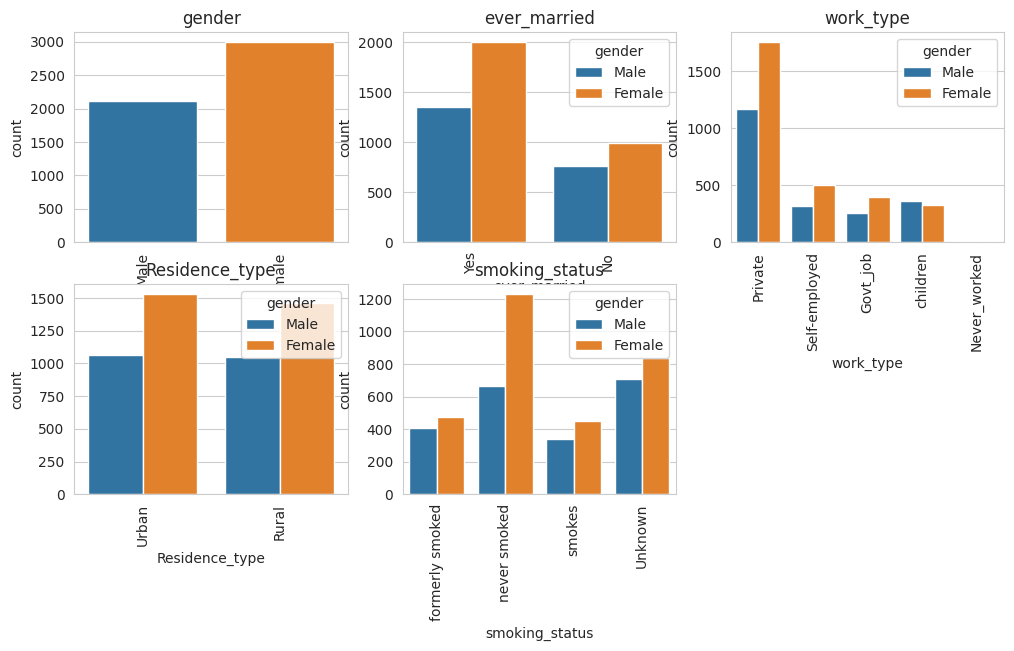

In [29]:
plt.figure(figsize=(12,6))
for i , col in enumerate(cat_cols,start=1):
    plt.subplot(2,3,i)
    sns.countplot(x=col,data=heal,hue='gender')
    plt.title(col)
    plt.xticks(rotation=90)

<Axes: xlabel='stroke', ylabel='age'>

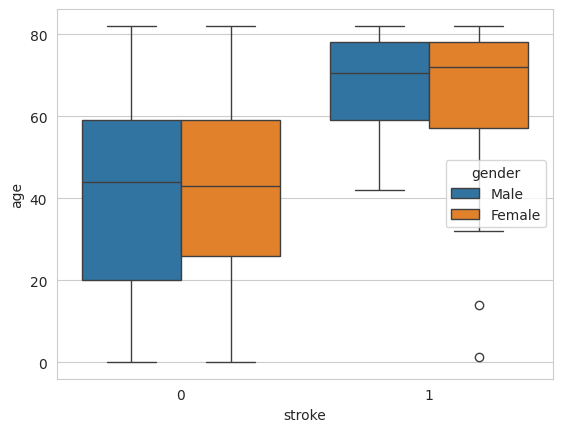

In [30]:
sns.boxplot(y='age',x='stroke',data=heal,hue='gender')

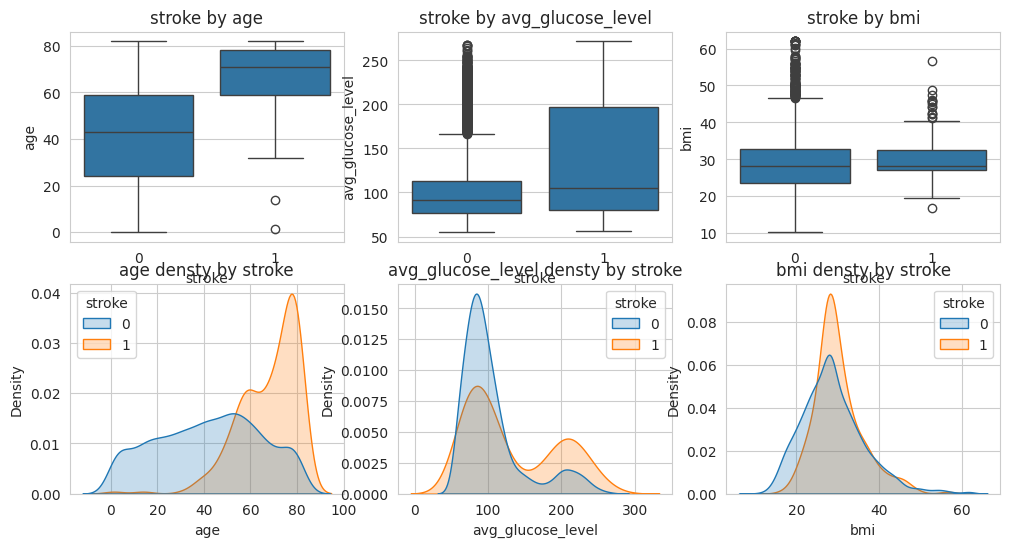

In [31]:
numeric_cols=heal.select_dtypes(include='float')
plt.figure(figsize=(12,6))
for i , col in enumerate(numeric_cols,start=1):
    plt.subplot(2,3,i)
    sns.boxplot(x='stroke',y=col,data=heal)
    plt.title(f'stroke by {col}')
    plt.subplot(2,3,i+3)
    sns.kdeplot(x=col,data=heal,hue='stroke',fill=True,common_norm=False)
    plt.title(f'{col} densty by stroke')
plt.show()

<Axes: >

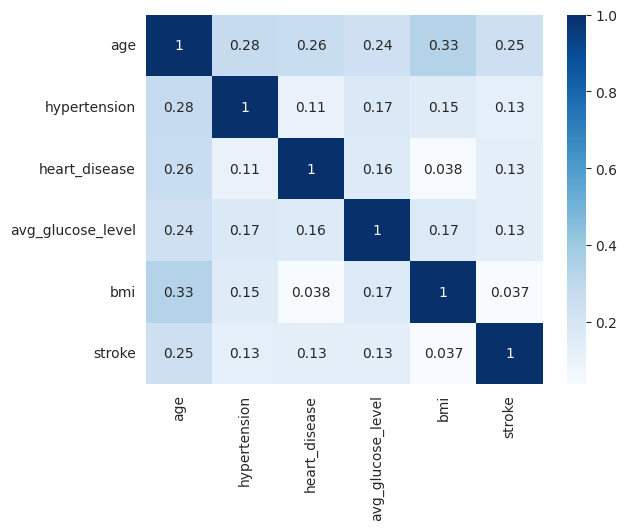

In [32]:
corr= heal.select_dtypes(include='number').drop(columns='id').corr()
sns.heatmap(corr,annot=True,cmap='Blues')

In [33]:
z=heal.select_dtypes(include='number').drop(columns='id').corr()[['stroke']].sort_values(['stroke'],ascending=False)
z

,stroke
stroke,1.000000
age,0.245239
heart_disease,0.134905
avg_glucose_level,0.131991
hypertension,0.127891
bmi,0.037248


<Axes: >

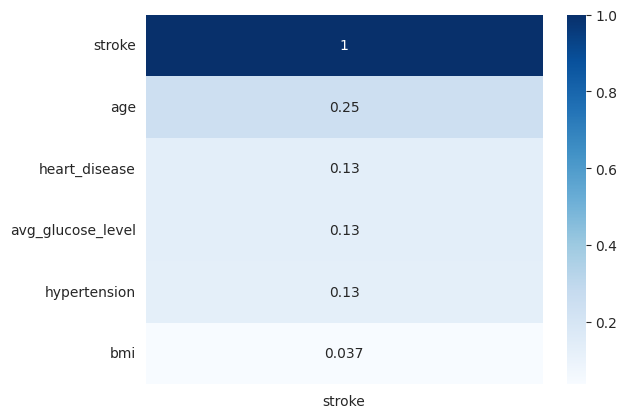

In [34]:
sns.heatmap(z,annot=True,cmap='Blues')

In [35]:
cat_cols.columns.tolist()

['gender', 'ever_married', 'work_type', 'Residence_type', 'smoking_status']

In [36]:
cat_cols.nunique()

gender            2
ever_married      2
work_type         5
Residence_type    2
smoking_status    4
dtype: int64

In [37]:
from sklearn.preprocessing import LabelEncoder
from sklearn.preprocessing import OneHotEncoder

In [38]:
for i in ['gender','ever_married','Residence_type']:
    le=LabelEncoder()
    heal[i]=le.fit_transform(heal[i])
heal.head()

,id,gender,age,hypertension,heart_disease,ever_married,work_type,Residence_type,avg_glucose_level,bmi,smoking_status,stroke
0,9046,1,67.0,0,1,1,Private,1,228.69,36.6,formerly smoked,1
1,51676,0,61.0,0,0,1,Self-employed,0,202.21,28.1,never smoked,1
2,31112,1,80.0,0,1,1,Private,0,105.92,32.5,never smoked,1
3,60182,0,49.0,0,0,1,Private,1,171.23,34.4,smokes,1
4,1665,0,79.0,1,0,1,Self-employed,0,174.12,24.0,never smoked,1


In [39]:
heal=pd.get_dummies(heal,columns=['work_type','smoking_status'],drop_first=True,dtype=int)


In [40]:
heal.head()

,id,gender,age,hypertension,heart_disease,ever_married,Residence_type,avg_glucose_level,bmi,stroke,work_type_Never_worked,work_type_Private,work_type_Self-employed,work_type_children,smoking_status_formerly smoked,smoking_status_never smoked,smoking_status_smokes
0,9046,1,67.0,0,1,1,1,228.69,36.6,1,0,1,0,0,1,0,0
1,51676,0,61.0,0,0,1,0,202.21,28.1,1,0,0,1,0,0,1,0
2,31112,1,80.0,0,1,1,0,105.92,32.5,1,0,1,0,0,0,1,0
3,60182,0,49.0,0,0,1,1,171.23,34.4,1,0,1,0,0,0,0,1
4,1665,0,79.0,1,0,1,0,174.12,24.0,1,0,0,1,0,0,1,0


In [41]:
from sklearn.model_selection import train_test_split

In [42]:
heal=heal.drop(columns='id')

In [43]:

x= heal.drop(columns=['stroke'])
y=heal['stroke']


In [44]:
X_train,X_test,y_train,y_test=train_test_split(x,y,train_size=0.8,random_state=42)

In [45]:
x=heal.select_dtypes(include='number')
x.nunique()

gender                               2
age                                104
hypertension                         2
heart_disease                        2
ever_married                         2
Residence_type                       2
avg_glucose_level                 3978
bmi                                411
stroke                               2
work_type_Never_worked               2
work_type_Private                    2
work_type_Self-employed              2
work_type_children                   2
smoking_status_formerly smoked       2
smoking_status_never smoked          2
smoking_status_smokes                2
dtype: int64

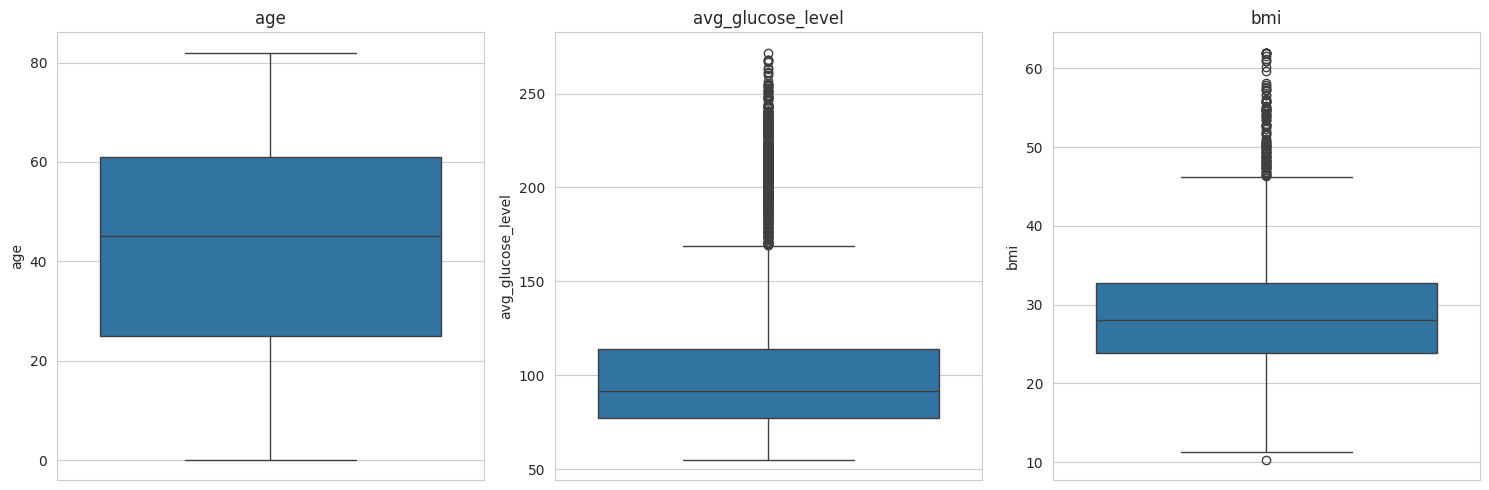

In [46]:
colsInScaler = ['age', 'avg_glucose_level', 'bmi']

plt.figure(figsize=(15, 5))
for i, col in enumerate(colsInScaler, start=1):
    plt.subplot(1, 3, i)
    sns.boxplot(y=col, data=heal)
    plt.title(col)
plt.tight_layout()
plt.show()

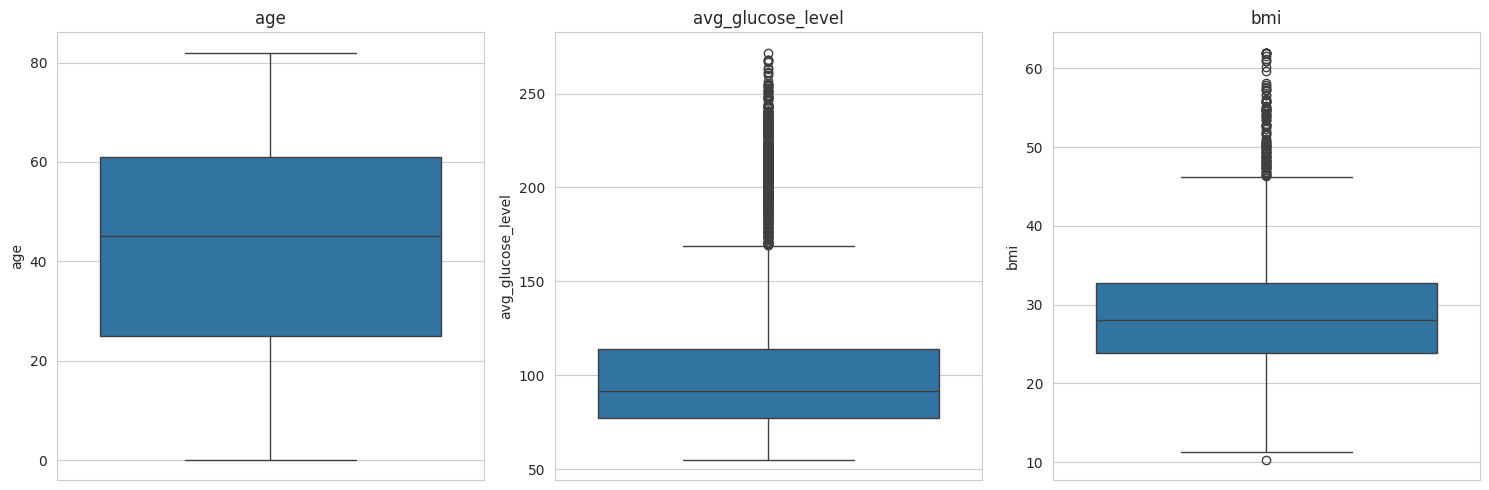

In [47]:
colsInScaler = ['age', 'avg_glucose_level', 'bmi']

plt.figure(figsize=(15, 5))
for i, col in enumerate(colsInScaler, start=1):
    plt.subplot(1, 3, i)
    sns.boxplot(y=col, data=heal)
    plt.title(col)
plt.tight_layout()
plt.show()

In [48]:
colsInScaler=['age','avg_glucose_level','bmi']
from sklearn.preprocessing import MinMaxScaler,StandardScaler,RobustScaler
scaler= RobustScaler()
X_train[colsInScaler]=scaler.fit_transform(X_train[colsInScaler])
X_test[colsInScaler]=scaler.transform(X_test[colsInScaler])

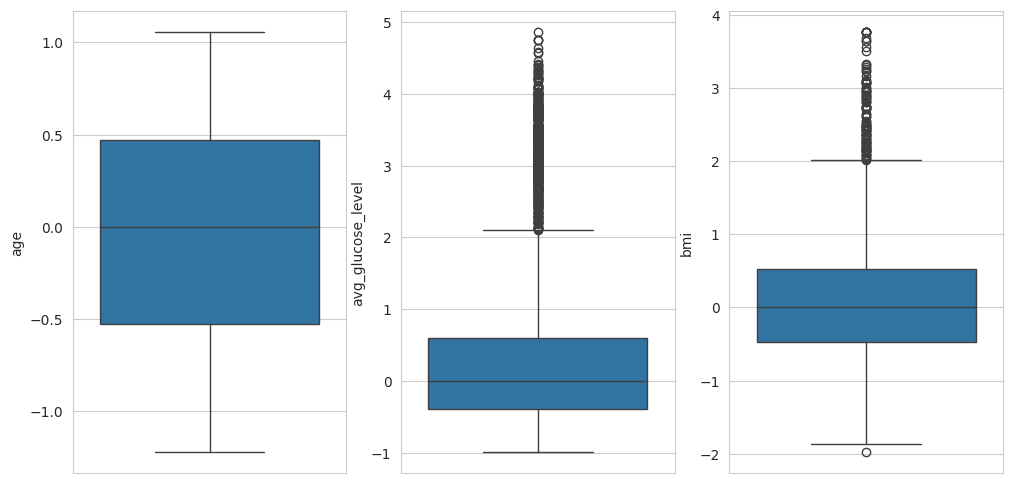

In [49]:
plt.figure(figsize=(12,6))
for i , col in enumerate(colsInScaler,start=1):
    plt.subplot(1,3,i)
    sns.boxplot(y=col,data=X_train)

In [50]:
from imblearn.over_sampling import RandomOverSampler
from imblearn.under_sampling import RandomUnderSampler
from imblearn.over_sampling import SMOTE

In [51]:
y.value_counts() / len(y)*100



stroke
0    95.126248
1     4.873752
Name: count, dtype: float64

In [52]:
rus=RandomUnderSampler(random_state=42)
x_rus,y_rus=rus.fit_resample(X_train,y_train)


In [53]:
y_rus.value_counts()

stroke
0    187
1    187
Name: count, dtype: int64

In [54]:
ros=RandomOverSampler(random_state=42)
x_ros,y_ros=ros.fit_resample(X_train,y_train)

In [55]:
y_ros.value_counts()

stroke
0    3900
1    3900
Name: count, dtype: int64

In [56]:
smote=SMOTE(random_state=42)
x_somte,y_somte=smote.fit_resample(X_train,y_train)

In [57]:
y_somte.value_counts()

stroke
0    3900
1    3900
Name: count, dtype: int64